# Lab 6: Unsupervised Learning — Clustering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NgKhiem69/datascience_course/blob/main/labs/06-clustering/Clustering%20with%20Scikitlearn.ipynb)

**Nội dung:** phân cụm bộ dữ liệu Iris bằng **K-Means**, chọn số cụm *k* bằng phương pháp Elbow và Silhouette, trực quan hoá bằng PCA, đánh giá so với nhãn thật, so sánh với Agglomerative Clustering và DBSCAN; cuối cùng áp dụng K-Means phân nhóm sinh viên từ `studyhours.csv` trên GitHub.

## 0. Thiết lập môi trường (Google Colab)

Dữ liệu được đọc trực tiếp từ thư mục `data/` của repo GitHub qua đường dẫn *raw*, nên không cần upload file hay mount Google Drive.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Đường dẫn raw tới thư mục data trên GitHub
GITHUB_USER, GITHUB_REPO, BRANCH = "NgKhiem69", "datascience_course", "main"
DATA_URL = f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/{BRANCH}/data"

def data_path(filename):
    """Trả về URL raw của một file trong thư mục data/ của repo."""
    return f"{DATA_URL}/{filename}"

# Kiểm tra đang chạy trên Colab hay máy local
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running on Colab:", IN_COLAB)
print("Data URL:", DATA_URL)

Running on Colab: False
Data URL: https://raw.githubusercontent.com/NgKhiem69/datascience_course/main/data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, accuracy_score, adjusted_rand_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from scipy.stats import mode

RANDOM_STATE = 0

## 1. Dữ liệu Iris

Trong học không giám sát, mô hình **không được dùng nhãn** `y` khi huấn luyện. Ta chỉ dùng `y` ở bước cuối để kiểm tra xem các cụm tìm được có khớp với loài hoa thật hay không.

In [3]:
iris = load_iris()
X = iris.data
y = iris.target
print("X:", X.shape)
print("Nhãn thật (chỉ dùng để đánh giá):\n", y)
pd.DataFrame(X, columns=iris.feature_names).describe().round(2)

X: (150, 4)
Nhãn thật (chỉ dùng để đánh giá):
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 2. K-Means với k = 3

In [4]:
km = KMeans(n_clusters=3, init="k-means++", max_iter=300, n_init=10, random_state=RANDOM_STATE)
y_kmeans = km.fit_predict(X)
labels = km.labels_

print("Số điểm mỗi cụm:", np.bincount(labels))
print(f"Inertia (tổng bình phương khoảng cách tới tâm cụm): {km.inertia_:.2f}")
print(f"Silhouette score (k=3): {silhouette_score(X, labels):.4f}")
print("Tâm các cụm:\n", pd.DataFrame(km.cluster_centers_, columns=iris.feature_names).round(2))

Số điểm mỗi cụm: [62 50 38]
Inertia (tổng bình phương khoảng cách tới tâm cụm): 78.85
Silhouette score (k=3): 0.5528
Tâm các cụm:
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0               5.90              2.75               4.39              1.43
1               5.01              3.43               1.46              0.25
2               6.85              3.07               5.74              2.07


## 3. Đánh giá so với nhãn thật

Nhãn cụm của K-Means là tuỳ ý (cụm 0 không nhất thiết là *setosa*), nên ta ánh xạ mỗi cụm sang nhãn thật xuất hiện nhiều nhất trong cụm đó rồi mới tính accuracy. Ngoài ra dùng **Adjusted Rand Index (ARI)** — chỉ số không phụ thuộc vào việc đặt tên cụm (1 = khớp hoàn toàn, ~0 = ngẫu nhiên).

K-means accuracy: 89.33%
Adjusted Rand Index: 0.7302


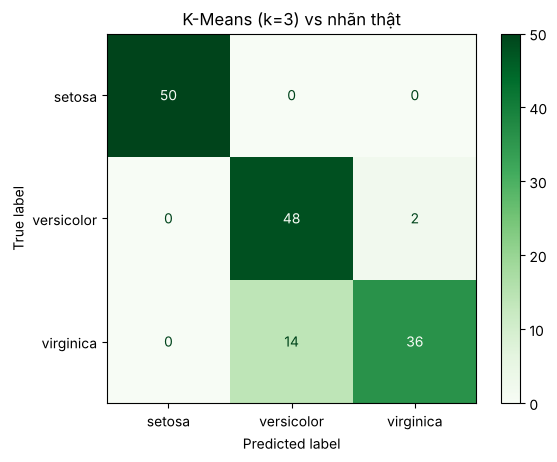

In [5]:
def map_clusters_to_labels(cluster_labels, true_labels):
    """Gán mỗi cụm thành nhãn thật phổ biến nhất trong cụm."""
    mapped = np.zeros_like(cluster_labels)
    for c in np.unique(cluster_labels):
        mask = cluster_labels == c
        mapped[mask] = mode(true_labels[mask], keepdims=True).mode[0]
    return mapped

predicted_labels = map_clusters_to_labels(labels, y)
print(f"K-means accuracy: {accuracy_score(y, predicted_labels) * 100:.2f}%")
print(f"Adjusted Rand Index: {adjusted_rand_score(y, labels):.4f}")

ConfusionMatrixDisplay(confusion_matrix(y, predicted_labels), display_labels=iris.target_names).plot(cmap="Greens")
plt.title("K-Means (k=3) vs nhãn thật")
plt.show()

## 4. Chọn số cụm k

- **Elbow method:** vẽ inertia theo k, chọn điểm "khuỷu tay" nơi inertia bắt đầu giảm chậm.
- **Silhouette:** đo mức độ một điểm gần cụm của nó hơn so với cụm khác (−1 → 1, càng cao càng tốt).

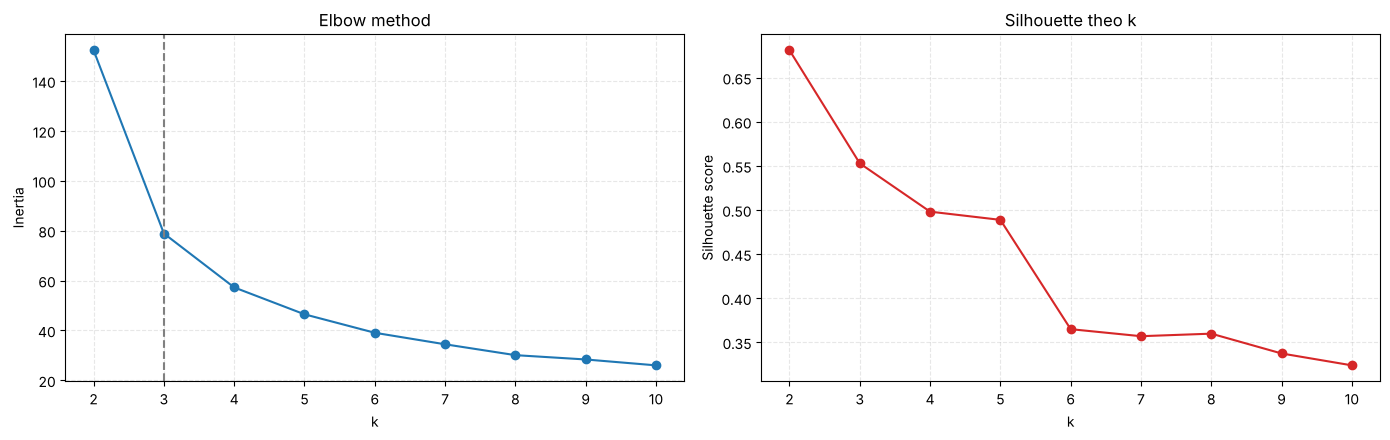

,inertia,silhouette
k,,
2,152.3480,0.6810
3,78.8514,0.5528
4,57.2285,0.4981
5,46.4462,0.4887
6,39.0400,0.3648
7,34.4202,0.3569
8,30.0646,0.3597
9,28.3326,0.3373
10,25.9726,0.3238


In [6]:
k_range = range(2, 11)
inertias, silhouettes = [], []
for k in k_range:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(k_range, inertias, "o-")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow method")
axes[0].axvline(3, color="gray", linestyle="--")
axes[1].plot(k_range, silhouettes, "o-", color="#d62728")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette theo k")
for ax in axes:
    ax.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame({"k": list(k_range), "inertia": inertias, "silhouette": silhouettes}).set_index("k").round(4)

**Nhận xét:** silhouette cao nhất ở **k = 2** vì *versicolor* và *virginica* nằm sát nhau, còn *setosa* tách biệt hẳn. Đồ thị elbow có khuỷu ở k = 2–3. Biết trước có 3 loài hoa nên k = 3 hợp lý về mặt ý nghĩa — đây là ví dụ cho thấy các chỉ số nội tại không phải lúc nào cũng chọn ra đúng số nhóm "thật".

## 5. Trực quan hoá bằng PCA

Giảm 4 chiều xuống 2 chiều để vẽ.

Tỉ lệ phương sai giữ lại: [0.925 0.053] → tổng 0.978


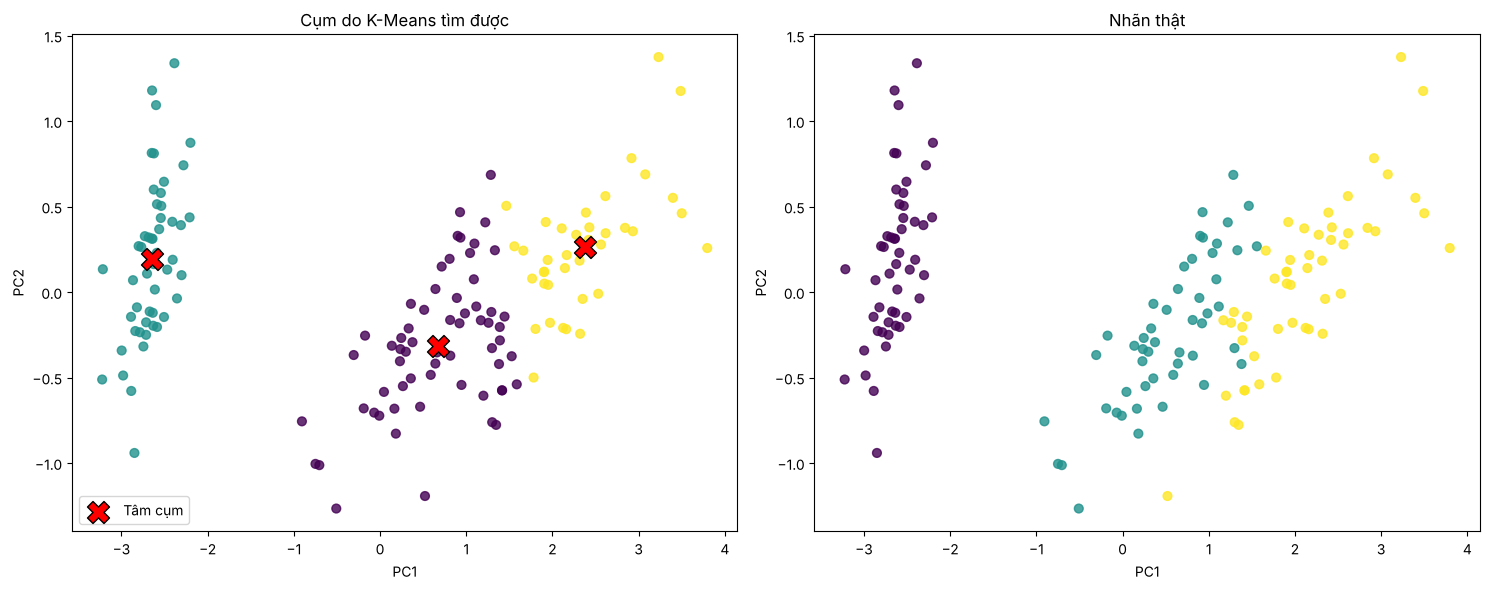

In [7]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)
centers_2d = pca.transform(km.cluster_centers_)
print("Tỉ lệ phương sai giữ lại:", pca.explained_variance_ratio_.round(3),
      "→ tổng", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sc = axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap="viridis", s=40, alpha=0.8)
axes[0].scatter(centers_2d[:, 0], centers_2d[:, 1], c="red", marker="X", s=250, edgecolor="black",
                label="Tâm cụm")
axes[0].set_title("Cụm do K-Means tìm được")
axes[0].legend()
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="viridis", s=40, alpha=0.8)
axes[1].set_title("Nhãn thật")
for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

## 6. Ảnh hưởng của chuẩn hoá dữ liệu

K-Means dựa trên khoảng cách Euclid nên thang đo của đặc trưng ảnh hưởng tới kết quả.

In [8]:
X_scaled = StandardScaler().fit_transform(X)
km_scaled = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)

pd.DataFrame({
    "Dữ liệu": ["Gốc", "Chuẩn hoá (StandardScaler)"],
    "ARI": [adjusted_rand_score(y, labels), adjusted_rand_score(y, km_scaled.labels_)],
    "Accuracy": [accuracy_score(y, predicted_labels),
                 accuracy_score(y, map_clusters_to_labels(km_scaled.labels_, y))],
}).set_index("Dữ liệu").round(4)

,ARI,Accuracy
Dữ liệu,,
Gốc,0.7302,0.8933
Chuẩn hoá (StandardScaler),0.6201,0.8333


Với Iris, các đặc trưng đều đo bằng cm và cùng cỡ nên chuẩn hoá không giúp ích (thậm chí kém hơn). Với dữ liệu có thang đo chênh lệch (ví dụ: tuổi và thu nhập) thì chuẩn hoá gần như bắt buộc.

## 7. So sánh với các thuật toán phân cụm khác

In [9]:
algorithms = {
    "K-Means (k=3)": KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE),
    "Agglomerative (ward, k=3)": AgglomerativeClustering(n_clusters=3, linkage="ward"),
    "DBSCAN (eps=0.6, min_samples=5)": DBSCAN(eps=0.6, min_samples=5),
}
rows, all_labels = [], {}
for name, algo in algorithms.items():
    lab = algo.fit_predict(X)
    all_labels[name] = lab
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    rows.append({
        "Thuật toán": name,
        "Số cụm": n_clusters,
        "Điểm nhiễu": int((lab == -1).sum()),
        "Silhouette": silhouette_score(X, lab) if n_clusters > 1 else np.nan,
        "ARI": adjusted_rand_score(y, lab),
    })
pd.DataFrame(rows).set_index("Thuật toán").round(4)

,Số cụm,Điểm nhiễu,Silhouette,ARI
Thuật toán,,,,
K-Means (k=3),3,0,0.5528,0.7302
"Agglomerative (ward, k=3)",3,0,0.5543,0.7312
"DBSCAN (eps=0.6, min_samples=5)",2,9,0.5382,0.5370


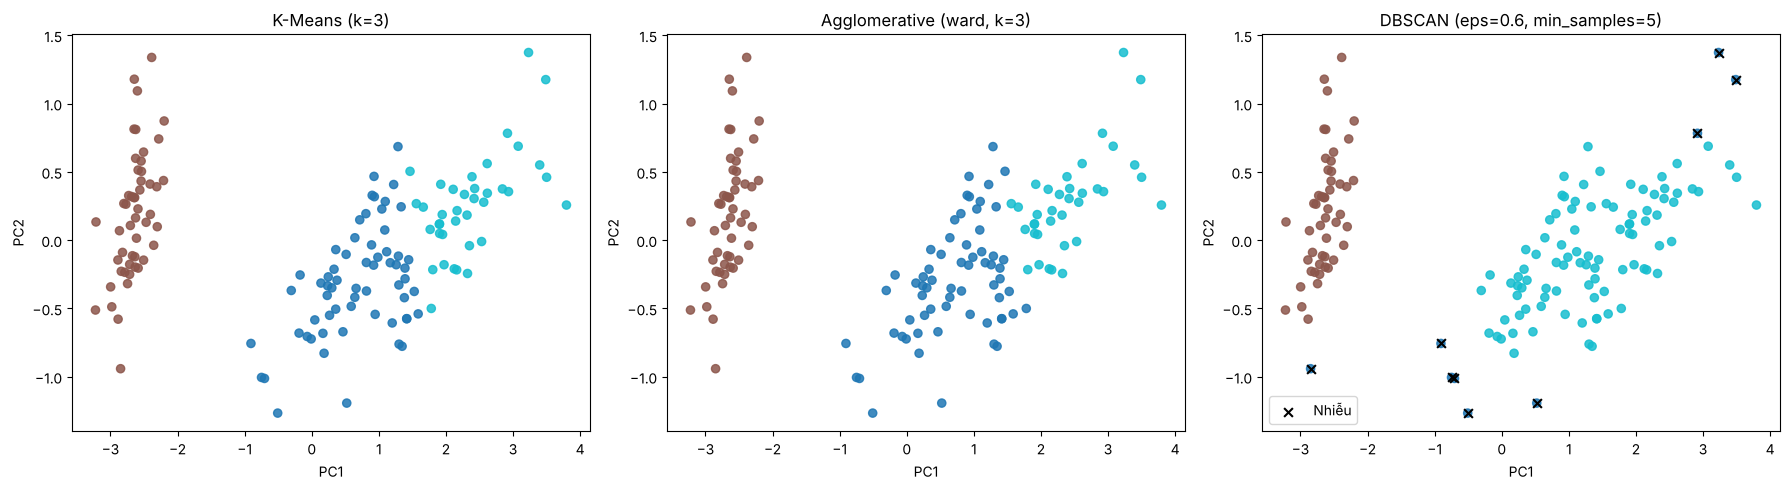

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, lab) in zip(axes, all_labels.items()):
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=lab, cmap="tab10", s=35, alpha=0.85)
    if (lab == -1).any():
        ax.scatter(X_2d[lab == -1, 0], X_2d[lab == -1, 1], c="black", marker="x", s=40, label="Nhiễu")
        ax.legend()
    ax.set_title(name)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

DBSCAN tự xác định số cụm dựa trên mật độ và đánh dấu điểm nhiễu (-1); trên Iris nó thường chỉ tìm ra 2 cụm vì *versicolor* và *virginica* liền mật độ với nhau.

## 8. Ứng dụng: phân nhóm sinh viên theo giờ học và điểm thi (`studyhours.csv`)

In [11]:
sh = pd.read_csv(data_path("studyhours.csv"))
X_sh = StandardScaler().fit_transform(sh[["Study Hours", "Exam Score"]])

km_sh = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_sh)
sh["Cluster"] = km_sh.labels_
print(f"Silhouette: {silhouette_score(X_sh, km_sh.labels_):.3f}")

summary = sh.groupby("Cluster")[["Study Hours", "Exam Score"]].agg(["mean", "count"]).round(1)
summary

Silhouette: 0.504


Study Hours       Exam Score      
               mean count       mean count
Cluster                                   
0              16.2    11       76.5    11
1              23.3    12       93.0    12
2               6.3    10       50.5    10

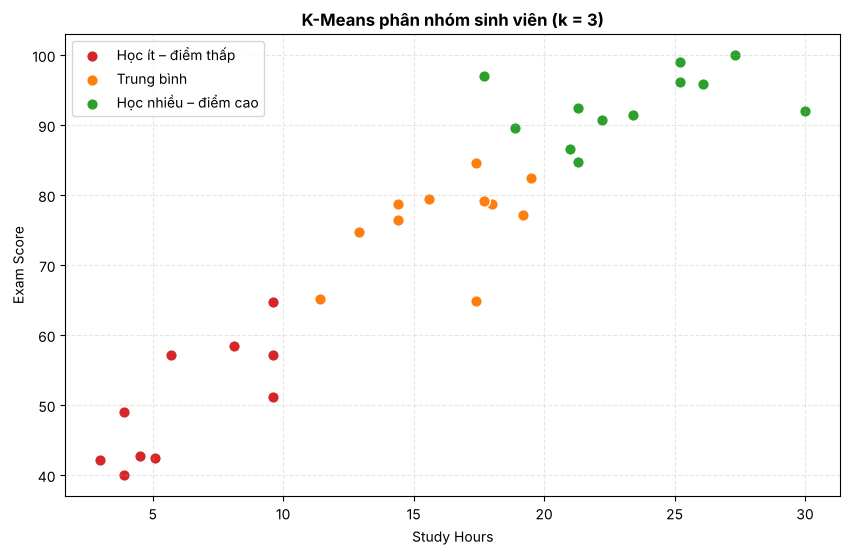

In [12]:
# Đặt tên nhóm theo điểm trung bình tăng dần
order = sh.groupby("Cluster")["Exam Score"].mean().sort_values().index
names = dict(zip(order, ["Học ít – điểm thấp", "Trung bình", "Học nhiều – điểm cao"]))
sh["Group"] = sh["Cluster"].map(names)

plt.figure(figsize=(10, 6))
for c, color in zip(order, ["#d62728", "#ff7f0e", "#2ca02c"]):
    part = sh[sh["Cluster"] == c]
    plt.scatter(part["Study Hours"], part["Exam Score"], s=70, color=color,
                edgecolor="white", label=names[c])
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("K-Means phân nhóm sinh viên (k = 3)", weight="bold")
plt.legend()
plt.grid(linestyle="--", alpha=0.3)
plt.show()

## Tổng kết

- K-Means (k = 3) khớp khá tốt với 3 loài hoa Iris; *setosa* được tách hoàn toàn, sai số nằm ở vùng giao giữa *versicolor* và *virginica*.
- Elbow và silhouette là công cụ gợi ý k, nhưng cần kết hợp hiểu biết về bài toán.
- Agglomerative cho kết quả tương tự K-Means; DBSCAN phù hợp với cụm có hình dạng bất kỳ và dữ liệu có nhiễu.